In [1]:
import numpy as np
import matplotlib.pyplot as plt
import torch.nn as nn
import torch

# Problem 1:

## a: NLP
Please discuss the recent trend of rapidly increasing sizes of NLP architectures. 

The ELMo and BERT embedding methods pioneered the use of tokenization for NLP which in turn led to training models using more and more data and parameters. They led to the development of GPT-1 which sparked a new era of generative NLP models. These models were fine-tuned in various ways to gain marginal improvements but the real breakthrough came with the introduction of GPT-2, which outperformed previous models without any finetuning at all. GPT-2 was just an extension of GPT-1 with a larger context size and more normalization, which led to the conclusion that simply increasing the size of models was enough to achieve better performance. Naturally this led to AI researchers increasing the size of their models even further and the rest is history.

## b: Transfer Learning

Classify the following example of transfer learning. More exactly, what are the domains and tasks, and which are being changed?

Source: Using a step counter to monitor exercise in healthy people.

Target: Using a step counter to indicate recovery progression in a patient

The feature space of both the source ($X_S$) and target ($X_T$) can be the same, which could be an average step count per day in the span of a week. Mathematically this would be represented as vectors of 7 natural numbers. The marginal distribution would however be different, as $P(X_S)$ representing healthy people will have a higher average compared to the $P(X_T)$ representing recovering patients.

The label space in the source as I understand it would be a binary classification of whether or not the person exercises i.e. $y_S \in \{0,1\}$, where 0 means they don't exercise and 1 means they do. The target is also binary classification but the labels represent different outputs i.e. $y_T \in \{0,1\}$, where 0 means the patient's condition isn't improving and 1 means it is. The task functions will therefore also be different, where $f_S$ maps step counts to exercise status and $f_T$ maps step counts to recovery progression.

This means that both the domain and task are changed when going from source to target. Since the task is changed, this is an example of inductive learning.

## c: Attention
Assume dotproduct attention, and that the hidden states of the encoder layer are [0,1,4],[-1,1,2],[1,1,1],[2,1,1]. If the activation for the previous decoder is [0.1,1,-2], what is the attention-context vector?

To calculate the context vector, the alignments $a_{ij}$ are first calculated with python using the dot product
$$
a_{ij} = h_j s_{i-1}
$$

In [2]:
h = np.array([[0, 1, 4], [-1, 1, 2], [1, 1, 1], [2, 1, 1]])
s = np.array([0.1, 1, -2])
a = h @ s
a

array([-7. , -3.1, -0.9, -0.8])

The attention weights are then found by applying the softmax function to the aligments

In [3]:
alpha = np.exp(a) / np.sum(np.exp(a))
alpha

array([0.00101111, 0.04995145, 0.45081253, 0.4982249 ])

Lastly the context vector is calculated as the weighted sum of the hidden states

In [4]:
c = alpha @ h # numpys dot product is practically a weighted sum in this case (same as a running sum across a for loop)
c

array([1.39731088, 1.        , 1.05298479])

## d: Transformers
Explain the 'positional encoding' step for transformers. Why is it done, how is it done?

Positional encoding is the process of adding vectors to the input embeddings to provide positional information to the model. This is done since self-attention in itself does not contain any positional information since it has no residual connections or recurrence. Order information is important for language processing since sentence structure can change entire sentences and meaning of words and sentence structure is just ordering of the words. The vector which is added to the input embeddings has to be unique for each position and be extendable to any length of input. The popular method used to achieve this is to use sine and cosine functions of different frequencies to calculate the values of the positional encoding vector for each position since it can be scaled indefinitely with respect to input dimensions.

## e: Bounding box detection:
Given a dataset with two classes; cats and dogs, and the following detections:

TP = True positive

FP = False positive

cat_det = [TP, FP, TP, FP, TP]

pred_scores_cat = [0.7, 0.3, 0.5, 0.6, 0.5]

dog_det = [FP, TP, TP, FP, TP, TP]

pred_scores_dog = [0.4, 0.3, 0.9, 0.5, 0.6, 0.7]

There are in total 3 cats and 4 dogs in the images.

Calculate the mean average precision (mAP)

First of all a table is created for each class to list the detection in order of decreasing confidence. This table is made to look at precision and recall values as the confidence threshold is lowered.

**Cats:**

\begin{table}[htbp]
  \centering
  \begin{tabular}{c|c|c|c|c}
    \hline
    \textbf{Box\#} & \textbf{Confidence} & \textbf{TP/FP} & \textbf{Precision} & \textbf{Recall} \\
    \hline
    0 & 1 & - & 1 & 0 \\
    1 & 0.7 & TP & 1/1 & 1/3 \\
    2 & 0.6 & FP & 1/2 & 1/3 \\
    3 & 0.5 & TP & 2/3 & 2/3 \\
    4 & 0.5 & TP & 3/4 & 3/3 \\
    5 & 0.3 & FP & 3/5 & 3/3 \\
    \hline
  \end{tabular}
  \caption{Evaluation metrics per bounding box.}
  \label{tab:bounding_box_metrics}
\end{table}

**Dogs:**

\begin{table}[htbp]
  \centering
  \begin{tabular}{c|c|c|c|c}
    \hline
    \textbf{Box\#} & \textbf{Confidence} & \textbf{TP/FP} & \textbf{Precision} & \textbf{Recall} \\
    \hline
    0 & 1 & - & 1 & 0 \\
    1 & 0.9 & TP & 1/1 & 1/4 \\
    2 & 0.7 & TP & 2/2 & 2/4 \\
    3 & 0.6 & TP & 3/3 & 3/4 \\
    4 & 0.5 & FP & 3/4 & 3/4 \\
    5 & 0.4 & FP & 3/5 & 3/4 \\
    6 & 0.3 & TP & 4/6 & 4/4 \\
    \hline
  \end{tabular}
  \caption{Evaluation metrics per bounding box.}
  \label{tab:bounding_box_metrics_2}
\end{table}

The average precision for each class is then calculated interpolating the "PR-curve" (not drawn here, but method is the same) using the equation:
$$
P_\text{interp}(R) = \max_{\tilde{R}:\tilde{R} \geq R} P(R)
$$

Where the average precision is the area under that curve calculated as the sum:
$$
AP = \sum_{n} (R_{n+1} - R_n) P_\text{interp}(R_{n+1})
$$

Since $(R_{n+1} - R_n)$ will be $\frac{1}{3}$ for all terms of $AP_{\text{cats}}$ and $\frac{1}{4}$ for all terms of $AP_{\text{dogs}}$, this results in the following average precision values:
$$
AP_{\text{cats}} = \frac{1}{3} \left( \frac{1}{1} + \frac{2}{3} + \frac{3}{4} \right) = \frac{29}{36} \approx 0.8056
$$
$$
AP_{\text{dogs}} = \frac{1}{4} \left( \frac{1}{1} + \frac{2}{2} + \frac{3}{3} + \frac{4}{6} \right) = \frac{11}{12} \approx 0.9167
$$

The mean average precision is then the mean of the AP of each class:
$$
mAP = \frac{AP_{\text{cats}} + AP_{\text{dogs}}}{2} = \frac{31}{36} \approx 0.8611
$$

## f: Semantic segmentation - FCN 1:
Given an image sized 1024x768x3 (width x height x channels), with 7 classes. What is the size of the target image if targets are one-hot encoded?


In semantic segmentation each pixel in the image is classified into classes, in this case the 7 classes. Since a one-hot encoding of 7 classes corresponds to a vector of length 7, the target image size will be 1024x768x7 (width x height x class labels).

## g: Semantic segmentation - FCN 2: 
What is a fully-convolutional network? When is it useful?


A fully-convolutional network is a neural network fully built up off convolutional layers, which allows them to output a feature map instead of a single vector unlike networks ending in fully connected layers. This is especially useful for semantic segmentation tasks since the feature map output is of the same size as the input and can be used to classify each pixel, where each channel in the output represents each class label of the task.

## h: Residual Networks:
Explain residual layers and their advantage. 

Residual layers or residual blocks are a based on normal feedforward layers, but with a skip connection that allows the input to bypass the processing done so it can be added directly to the output of the layer. This allows the network to have a better understanding of the input data/identity, which stabilizes the convergence of the network. Since adding the identity also takes the output closer to the identity, it inadvertently also solves the vanishing gradient problem.

## i: Intersection-Over-Union
Calculate the intersection over union in for these four bounding-boxes and target bounding boxes:

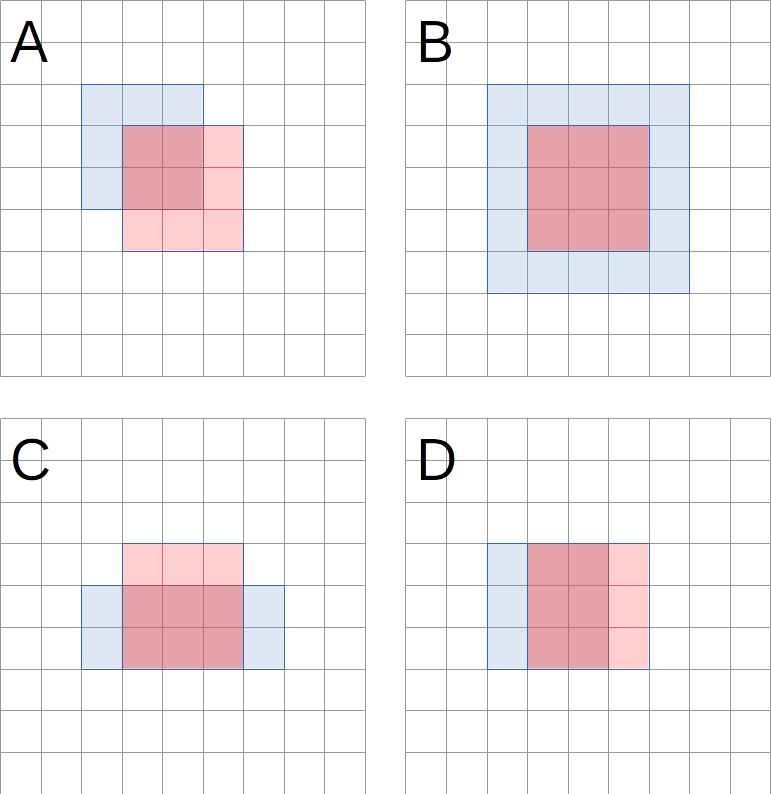

Each square is counted as 1. The intersection over union or Jaccard index is then calculated as follows:
$$
J(A_1, A_2) = \frac{4}{14} = \frac{2}{7} \approx 0.29
$$

$$
J(B_1, B_2) = \frac{9}{25} = 0.36
$$

$$
J(C_1, C_2) = \frac{6}{13} \approx 0.46
$$

$$
J(D_1, D_2) = \frac{6}{12} = 0.5
$$

## j: Variational autoencoders:
What are the strengths of a variational autoencoder (VAE) compared to an autoencoder (AE)?

The difference between a VAE and a normal AE is that the VAE encodes the input into a regularized probability distribution in the latent space instead of a discrete value. This allows the VAE to have a more continuous latent space which allows the decoder to sample from the latent space and generate both learned and new data, which is great for generative tasks.

$\pagebreak$

# Problem 2:

In this problem, you will build a waveform detector for 1D time series. Below is shared a piece of code defining a (train) dataset and a test set. As you will see when you open the file, the data is synthetic - a waveform is combined with a background 'noise' signal, allowing virtually infinite training data. 

The task is:

Using the dataset supplied below, create a neural network which can detect the ends of waveforms (marked by '1' in the labels).

You are free to use either GRU, LSTM, xLSTM, state space models or Transformers to do the task.

Dataset generation: data_setup

Use the 'waveformLoader' as data loader for your training data, and 'testX,testy' as the test data. Report your performance as an average loss over the test data and with a plot of 'testy' and 'net(testX)' as a function of time, such as as the figure below. Calculate also the f1 score for your detector. 

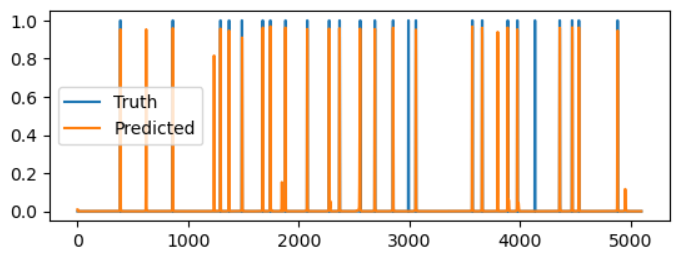

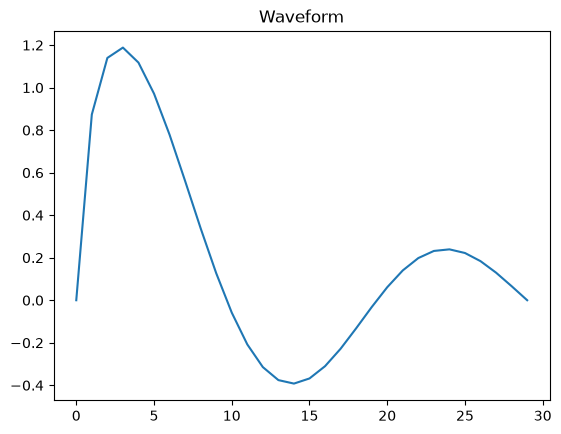

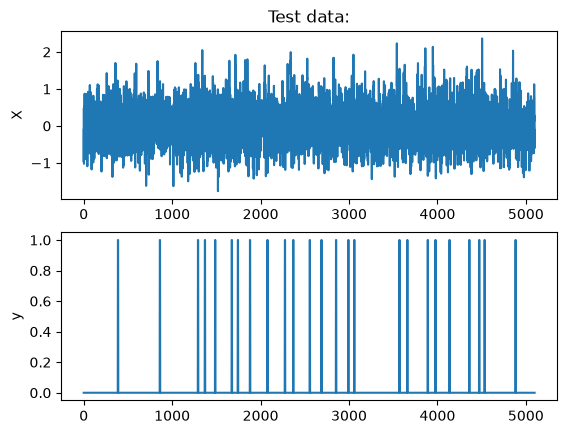

In [5]:
from dataset_setup import waveformLoader, testX, testy

To solve the task, a LSTM model was created. This model was chosen since it is relatively simple and still widely used.

In [6]:
class net(nn.Module):
    def __init__(self, input_size=1, hidden_size=20, num_layers=2, device='cpu'):
        super(net, self).__init__()
        self.lstm = nn.LSTM(input_size=input_size, hidden_size=hidden_size, num_layers=num_layers, batch_first=True)
        self.output = nn.Linear(hidden_size, 1)
        self.device = device

    def forward(self, x):
        lstm_out, _ = self.lstm(x)
        output = self.output(lstm_out)
        return output

The optimizer used is AdamW since it is one of the mostly used optimizers for deep learning. The loss function used is `BCEWithLogitsLoss` which is binary cross entropy loss, which is perfect for binary classification tasks such as this one, with an added sigmoid layer.

In [7]:
num_epochs = 500
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = net().to(device)

pos = sum(l.sum() for _, l in waveformLoader)
total = sum(l.numel() for _, l in waveformLoader)
pos_weight = (total - pos) / pos
criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight.to(device))
optimizer = torch.optim.AdamW(model.parameters(), lr=0.001)

for epoch in range(num_epochs):
    model.train()
    total_loss = 0

    for inputs, labels in waveformLoader:
        inputs, labels = inputs.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs = model(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        total_loss += loss.detach()

    if (epoch + 1) % 100 == 0:
        print(f'Epoch [{epoch + 1}/{num_epochs}], Loss: {(total_loss / len(waveformLoader)).item():.4f}')

torch.save(model.state_dict(), 'lstm_model.pth')

Epoch [100/500], Loss: 0.1302
Epoch [200/500], Loss: 0.0890
Epoch [300/500], Loss: 0.0601
Epoch [400/500], Loss: 0.0667
Epoch [500/500], Loss: 0.0522


In [8]:
model = net()
model.load_state_dict(torch.load('lstm_model.pth'))
model.to(device)

testX = testX.to(device)
testy = testy.to(device)

with torch.no_grad():
    model.eval()
    test_outputs = model(testX)
    test_predictions = torch.sigmoid(test_outputs).round()
    
    test_accuracy = (test_predictions == testy).float().mean()
    print(f'Test Accuracy: {test_accuracy:.4f}')

    test_loss = criterion(test_outputs[0], testy)
    print(f'Test Loss: {test_loss.item():.4f}')

Test Accuracy: 0.9855
Test Loss: 0.0636


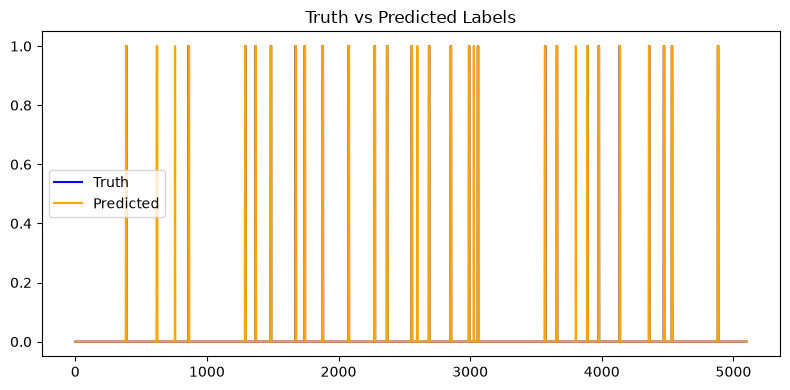

In [9]:
y_true = testy.squeeze().cpu().numpy()
y_pred = test_predictions[0].squeeze().cpu().numpy()

plt.figure(figsize=(8, 4))
plt.plot(y_true, label='Truth', color='blue')
plt.plot(y_pred, label='Predicted', color='orange')
plt.title('Truth vs Predicted Labels')
plt.legend(loc='center left')
plt.tight_layout()

To find the f1 score, the precision and recall also had to be calculated. Since they were also available, all three metrics are printed below. The f1 score function itself is implmented with heavy inspiration from a geeksforgeeks article.

In [10]:
# function taken from https://www.geeksforgeeks.org/deep-learning/how-to-calculate-the-f1-score-and-other-custom-metrics-in-pytorch/
def f1_score(y_true, y_pred):
    TP = ((y_pred == 1) & (y_true == 1)).sum().item()
    FP = ((y_pred == 1) & (y_true == 0)).sum().item()
    FN = ((y_pred == 0) & (y_true == 1)).sum().item()

    precision = TP / (TP + FP) if TP + FP > 0 else 0
    recall = TP / (TP + FN) if TP + FN > 0 else 0
    
    f1 = 2 * (precision * recall) / (precision + recall) if (precision + recall) > 0 else 0
    return precision, recall, f1

precision, recall, f1 = f1_score(testy, test_predictions[0])
print(f'Precision: {precision:.4f} \nRecall: {recall:.4f} \nF1 Score: {f1:.4f}')

Precision: 0.5747 
Recall: 1.0000 
F1 Score: 0.7299
